# Crime Data Recommendation System

## Data Processing

In [10]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Load data
csv_path = Path("data/chicago_crimes.csv")
if csv_path.exists():
    df = pd.read_csv(csv_path)
else:
    url = "https://data.cityofchicago.org/resource/ijzp-q8t2.csv?$limit=1000000"
    df = pd.read_csv(url)
    csv_path.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(csv_path, index=False)

# Only include the following crimes
crime_types = [
    "ROBBERY",
    "THEFT",
    "MOTOR VEHICLE THEFT",
    "BURGLARY",
    "CRIMINAL DAMAGE",
    "CRIMINAL TRESPASS",
]
df = df.loc[df["primary_type"].isin(crime_types)].copy()
print(f"Matching crime rows: {len(df):,}")

# Drop un-needed features

Matching crime rows: 516,156


## EDA - Exploratory Data Analysis

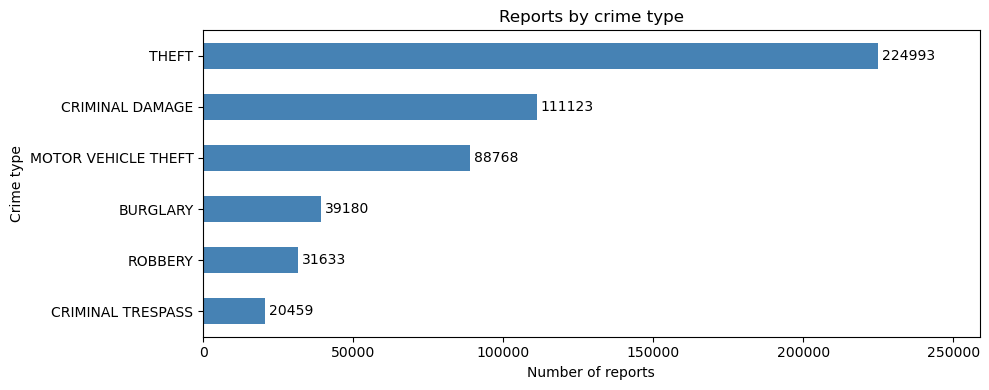

In [ ]:
# Distribution of crime types
crime_counts = df["primary_type"].value_counts().sort_values()
ax = crime_counts.plot.barh(figsize=(10, 4), color="steelblue")
ax.set(title="Reports by crime type", xlabel="Number of reports", ylabel="Crime type")
ax.bar_label(ax.containers[0], padding=3)
ax.margins(x=0.15)
plt.tight_layout()
plt.show()

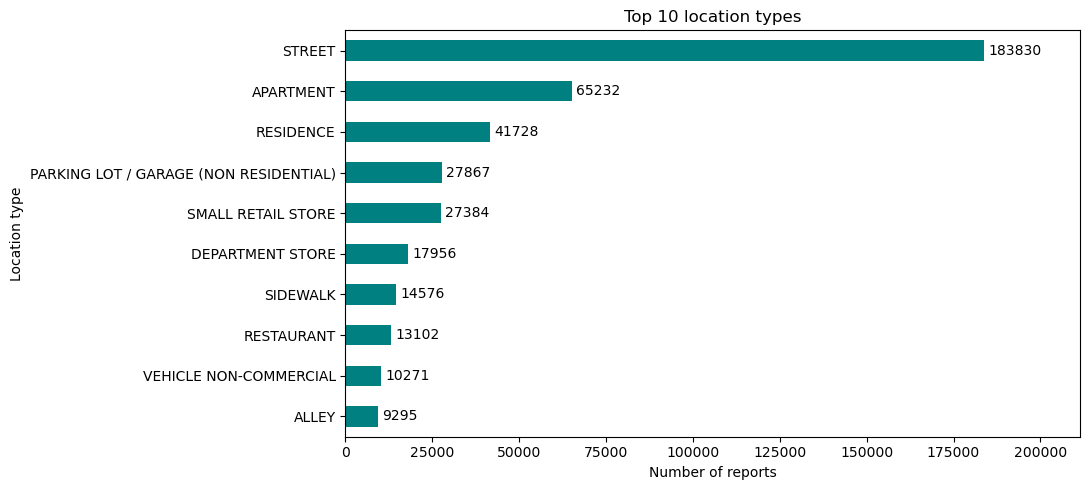

In [ ]:
# Distribution of locations
top_locations = df["location_description"].value_counts().head(10).sort_values()
ax = top_locations.plot.barh(figsize=(11, 5), color="teal")
ax.set(title="Top 10 location types", xlabel="Number of reports", ylabel="Location type")
ax.bar_label(ax.containers[0], padding=3)
ax.margins(x=0.15)
plt.tight_layout()
plt.show()

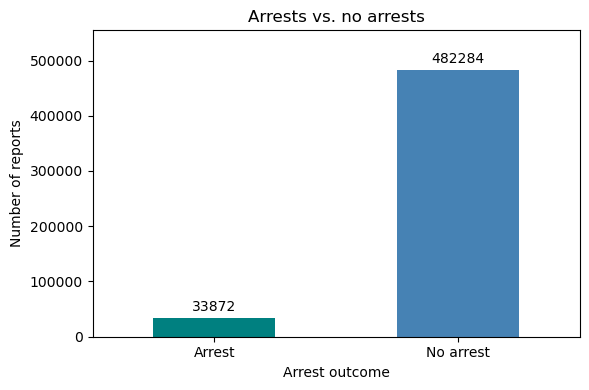

In [13]:
arrest_counts = df["arrest"].value_counts().reindex([True, False], fill_value=0)
arrest_counts.index = ["Arrest", "No arrest"]
ax = arrest_counts.plot.bar(figsize=(6, 4), color=["teal", "steelblue"], rot=0)
ax.set(title="Arrests vs. no arrests", xlabel="Arrest outcome", ylabel="Number of reports")
ax.bar_label(ax.containers[0], padding=3)
ax.margins(y=0.15)
plt.tight_layout()
plt.show()

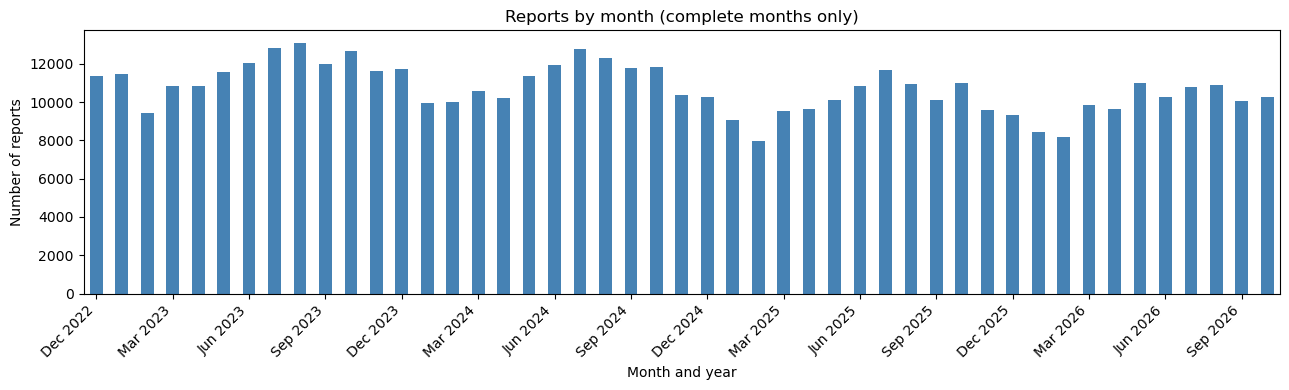

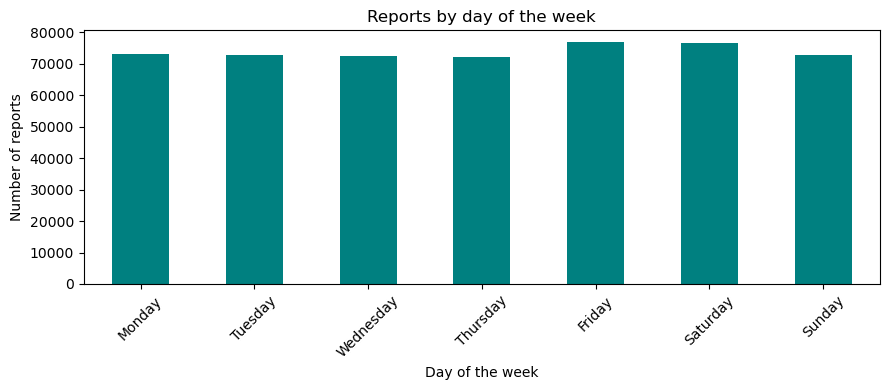

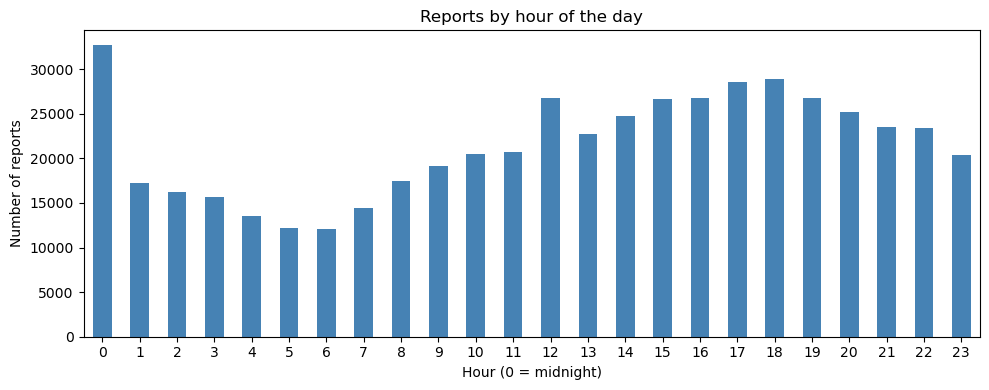

In [15]:
crime_dates = pd.to_datetime(df["date"], errors="coerce")
monthly_counts = crime_dates.dt.to_period("M").value_counts().sort_index()

# Compare only months fully covered by the cached sample.
monthly_counts = monthly_counts.loc[
    (monthly_counts.index.start_time >= crime_dates.min().normalize())
    & (monthly_counts.index.end_time.normalize() <= crime_dates.max().normalize())
]
monthly_counts.index = monthly_counts.index.strftime("%b %Y")

ax = monthly_counts.plot.bar(figsize=(13, 4), color="steelblue", rot=45)
label_step = max(1, len(monthly_counts) // 12)
ax.set_xticks(range(0, len(monthly_counts), label_step))
ax.set_xticklabels(monthly_counts.index[::label_step], rotation=45, ha="right")
ax.set(title="Reports by month (complete months only)", xlabel="Month and year", ylabel="Number of reports")
plt.tight_layout()
plt.show()


weekdays = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_counts = crime_dates.dt.day_name().value_counts().reindex(weekdays, fill_value=0)
ax = weekday_counts.plot.bar(figsize=(9, 4), color="teal", rot=45)
ax.set(title="Reports by day of the week", xlabel="Day of the week", ylabel="Number of reports")
plt.tight_layout()
plt.show()


hourly_counts = crime_dates.dt.hour.value_counts().reindex(range(24), fill_value=0)
ax = hourly_counts.plot.bar(figsize=(10, 4), color="steelblue", rot=0)
ax.set(title="Reports by hour of the day", xlabel="Hour (0 = midnight)", ylabel="Number of reports")
plt.tight_layout()
plt.show()

# Modeling

### Model 1 - Arrest Made (Rating Prediction)

### Model 2 - Location 

### Model 3 - Temporal Model

### Model 4 - Patrol Recommendation (Hybrid Ranking)

Giga model